# WorldSpeech `en_us` – Exploratory Data Analysis

This notebook explores the **metadata** of the WorldSpeech dataset, config `en_us`
(US House of Representatives floor proceedings). It is based on the metadata-only
scan produced by `scripts/scan_metadata.py`, which reads all columns **except**
`audio` from the parquet shards via HTTP range requests — the ~109 GB audio
payload is never downloaded for this analysis.

**What this notebook shows:** what the dataset contains (schema, row counts,
hours), quality distributions (CER, SNR, DNSMOS), temporal coverage
(`session_date`), transcript examples, and how many rows pass our candidate
filter thresholds.

**To regenerate the underlying data** (needs network access):
`python scripts/scan_metadata.py --split both`

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)
pd.set_option("display.max_colwidth", 80)

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print("Setup done")

Setup done


## Config

In [3]:
# Locate the repository root from the kernel's working directory,
# so the notebook runs no matter where it was launched from.
ROOT = Path.cwd()
while not (ROOT / "data" / "metadata").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

META_DIR = ROOT / "data" / "metadata"
TRAIN_PARQUET = META_DIR / "en_us_train_metadata.parquet"
TEST_PARQUET = META_DIR / "en_us_test_metadata.parquet"

for p in [TRAIN_PARQUET, TEST_PARQUET]:
    assert p.exists(), f"Missing {p} — run scripts/scan_metadata.py --split both first"
print(f"Repo root: {ROOT}")
print("Data files found")


Repo root: /Users/dudu/Audio-03
Data files found


## 1. Data overview

WorldSpeech `en_us` contains segments of US House of Representatives floor
proceedings. Each row is one speech segment with its transcript and quality
metadata. The `audio` column (24 kHz OGG Opus) is **not** part of this analysis.

In [4]:
train = pd.read_parquet(TRAIN_PARQUET)
test = pd.read_parquet(TEST_PARQUET)

overview = pd.DataFrame({
    "train": [train.shape[0], train["duration"].sum() / 3600,
              train["session_date"].min(), train["session_date"].max(),
              train["session_date"].nunique()],
    "test":  [test.shape[0], test["duration"].sum() / 3600,
              test["session_date"].min(), test["session_date"].max(),
              test["session_date"].nunique()],
}, index=["rows", "hours", "first session_date", "last session_date", "distinct dates"])
overview.loc["hours"] = overview.loc["hours"].round(1)
overview

,train,test
rows,666718,35336
hours,3525.5,186.600006
first session_date,2017-01-04,2017-01-04
last session_date,2026-05-04,2026-05-04
distinct dates,1415,1097


In [5]:
# Schema: column, dtype, short description
schema = pd.DataFrame({
    "column": train.columns,
    "dtype": [str(t) for t in train.dtypes],
}).set_index("column")
schema

,dtype
column,
human_transcript,str
asr_transcript,str
cer,float32
snr,float32
dnsmos_sig,float32
dnsmos_bak,float32
dnsmos_ovr,float32
dnsmos_p808,float32
duration,float32


**Field descriptions** (from the dataset card):

| Field | Meaning |
|---|---|
| `human_transcript` | Human-made transcript, cased and punctuated |
| `asr_transcript` | Automatic transcript produced by an ASR model |
| `cer` | Character error rate between the two transcripts (0 = identical) |
| `snr` | Signal-to-noise ratio in dB |
| `dnsmos_sig/bak/ovr/p808` | Deep-Noise-Suppression MOS: signal quality / background noise / overall / speech prediction |
| `duration` | Segment length in seconds |
| `source`, `source_url`, `source_start_s/end_s` | Origin of the segment within the source video |
| `session_date` | Date of the parliamentary session |
| `segment_id`, `language`, `country` | Identifiers and locale |

## 2. Quality and duration distributions

In [6]:
cols = ["cer", "snr", "dnsmos_ovr", "duration"]

desc = pd.concat({
    "train": train[cols].describe(percentiles=[.1, .25, .5, .75, .9]).T,
    "test": test[cols].describe(percentiles=[.1, .25, .5, .75, .9]).T,
}, axis=1)
desc.round(3)

train                                                         \
               count    mean    std     min     10%     25%     50%     75%   
cer         666718.0   0.088  0.069   0.000   0.017   0.036   0.069   0.122   
snr         666718.0  16.885  7.199  -1.730  10.457  12.492  15.353  19.469   
dnsmos_ovr  666718.0   3.229  0.202   0.871   2.994   3.138   3.265   3.361   
duration    666718.0  19.036  2.345  10.000  15.184  20.000  20.000  20.000   

                               test                                         \
               90%     max    count    mean    std     min     10%     25%   
cer          0.192    0.30  35336.0   0.088  0.069   0.000   0.017   0.036   
snr         25.012  100.00  35336.0  16.906  7.296  -1.766  10.498  12.486   
dnsmos_ovr   3.430    3.69  35336.0   3.229  0.199   1.009   2.998   3.137   
duration    20.000   20.00  35336.0  19.015  2.372  10.001  15.056  20.000   

                                             
               50%     75%     90%      max  
cer          0.069   0.123   0.193    0.300  
snr         15.360  19.481  25.023  100.000  
dnsmos_ovr   3.263   3.362   3.431    3.682  
duration    20.000  20.000  20.000   20.000

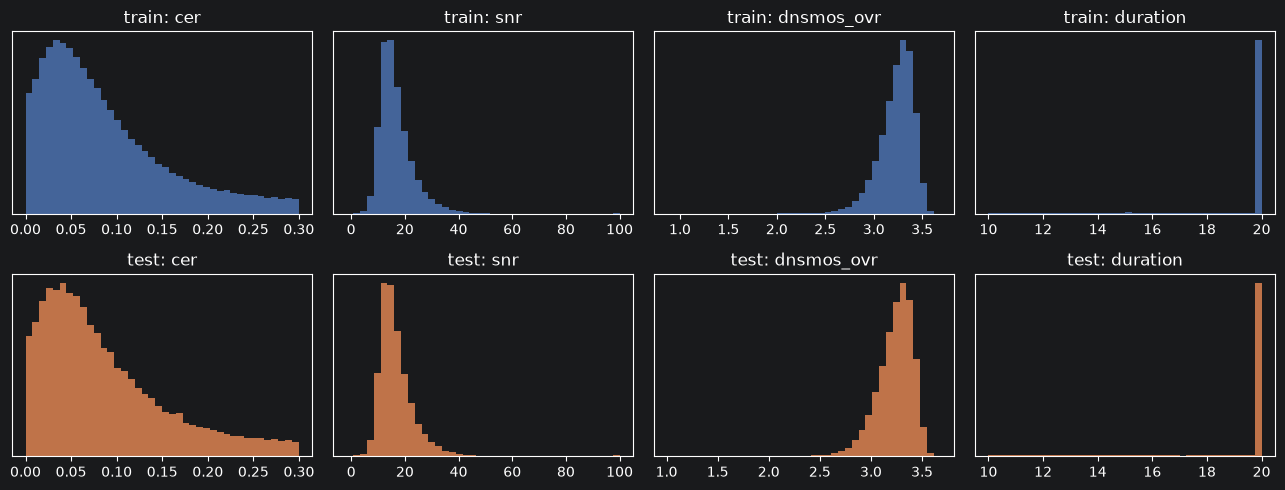

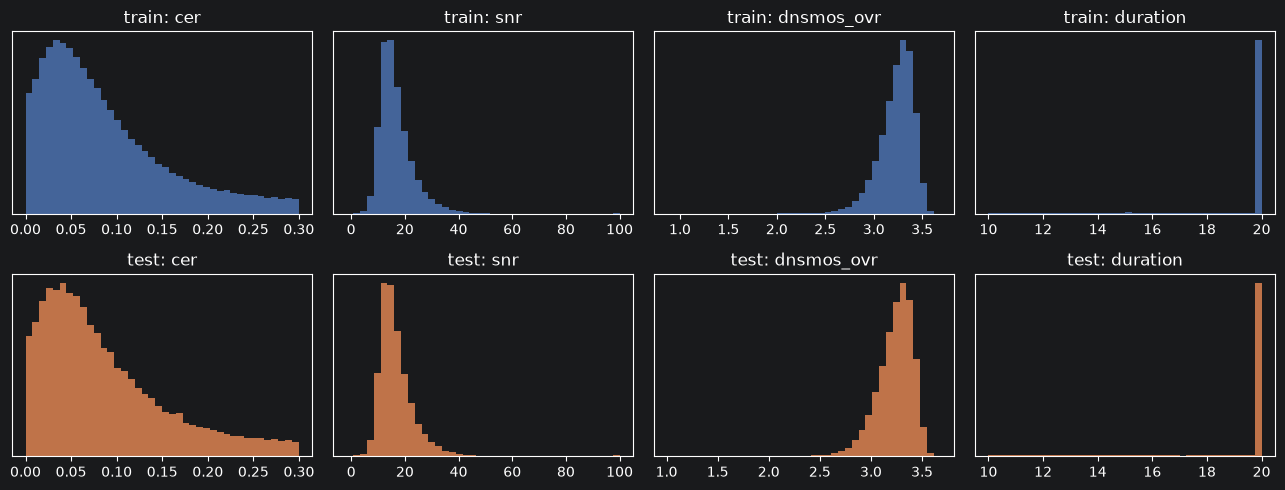

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for j, (df, name) in enumerate([(train, "train"), (test, "test")]):
    for i, col in enumerate(cols):
        ax = axes[j, i]
        ax.hist(df[col].dropna(), bins=40, color=["#4C72B0", "#DD8452"][j], alpha=.85)
        ax.set_title(f"{name}: {col}")
        ax.set_yticks([])
fig.tight_layout()
fig

**Reading the distributions:**

- `duration` is pre-capped: segments range from 10 to 20 s → a 3–20 s filter
  would keep everything; the binding filters are CER and noise.
- `cer` (character error rate between human and ASR transcript): median ≈ 0.07,
  90th percentile ≈ 0.19, hard cap at 0.30 (the dataset authors pre-filtered).
- `snr`: median ≈ 15 dB; a few rows have extreme values (up to 100 dB).
- `dnsmos_ovr`: overall quality mostly between 2.5 and 3.7.

## 3. Temporal coverage (`session_date`)

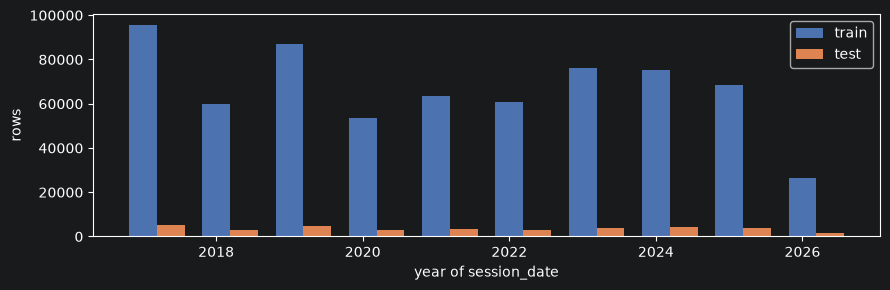

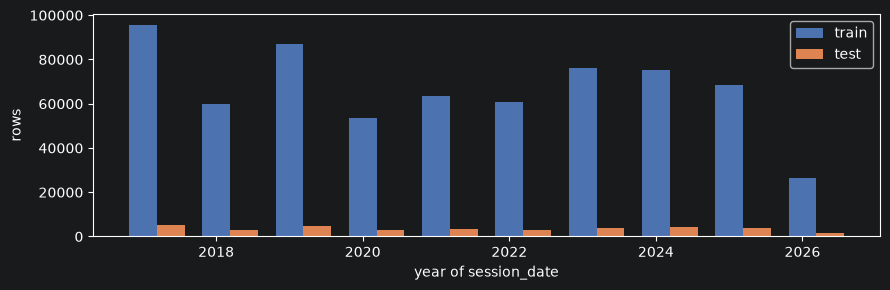

In [8]:
fig, ax = plt.subplots(figsize=(9, 3))
for df, name, color in [(train, "train", "#4C72B0"), (test, "test", "#DD8452")]:
    per_year = pd.to_datetime(df["session_date"]).dt.year.value_counts().sort_index()
    ax.bar(per_year.index + (0.0 if name == "train" else 0.38),
           per_year.values, width=0.38, label=name, color=color)
ax.set_xlabel("year of session_date")
ax.set_ylabel("rows")
ax.legend()
fig.tight_layout()
fig

In [9]:
train_dates = set(train["session_date"])
test_dates = set(test["session_date"])
overlap = train_dates & test_dates
print(f"distinct dates: train {len(train_dates)}, test {len(test_dates)}, "
      f"overlapping {len(overlap)} ({len(overlap) / len(test_dates):.0%} of test dates)")

distinct dates: train 1415, test 1097, overlapping 1097 (100% of test dates)


**Caveat:** train and test date ranges overlap almost completely. The dataset
provides **no speaker IDs**, so speakers may also appear in both splits. Any
split design must document this honestly (see datasheet).

## 4. Transcript examples

In [10]:
def show_example(df, label):
    row = df.loc[df["cer"].idxmax()]
    print(f"--- {label} (cer={row['cer']:.3f}, snr={row['snr']:.1f} dB) ---")
    print("HUMAN:", row["human_transcript"][:220])
    print("ASR:  ", row["asr_transcript"][:220])
    print()

show_example(test, "test row with HIGHEST CER")
show_example(test.nsmallest(5, "cer").tail(1), "test row with LOW CER (of 5 lowest)")

--- test row with HIGHEST CER (cer=0.300, snr=14.0 dB) ---
HUMAN: words are withdrawn. There was no objection. The SPEAKER pro tempore. The gentleman from New York is recognized. Mr. JONES. Mr. Speaker, the truth is, there is no good-faith argument for disenfranchising over 700,000 peo
ASR:   We have not consent to withdraw. General Regal says his words, the debate is going to continue. General from New York is recognized. Thank you, Mr. Speaker. The truth is there is no good faith argument for disenfranchisi

--- test row with LOW CER (of 5 lowest) (cer=0.000, snr=20.0 dB) ---
HUMAN: firms to notify investors before moving funds from one account to another in order to prevent abuses like those that occurred at MF Global prior to its bankruptcy.
ASR:   firms to notify investors before moving funds from one account to another in order to prevent abuses like those that occurred at MF Global prior to its bankruptcy.



The `human_transcript` is cased and punctuated — a key reason this dataset fits
our project: spaCy NER needs proper capitalization, and named entities (names of
representatives, places, organisations, bills) occur frequently in parliamentary
speech.

## 5. Candidate filter check

Proposed thresholds for the dataset package (to be frozen in
`configs/filter_v1.yaml`): CER < 0.10 (train) / < 0.05 (test), duration 3–20 s,
SNR ≥ 12.5 dB, DNSMOS-ovr ≥ 3.14, RMS > −40 dBFS (audio-side, not checkable here).

In [11]:
def passes(df, cer_max):
    m = ((df["cer"] < cer_max)
         & df["duration"].between(3, 20)
         & (df["snr"] >= 12.5)
         & (df["dnsmos_ovr"] >= 3.14))
    return m

for df, name, cer_max in [(train, "train", 0.10), (test, "test", 0.05)]:
    m = passes(df, cer_max)
    print(f"{name}: {m.sum():,} of {len(df):,} rows pass ({m.mean():.0%}) "
          f"= {df.loc[m, 'duration'].sum() / 3600:,.0f} h")

train: 272,307 of 666,718 rows pass (41%) = 1,443 h
test: 7,949 of 35,336 rows pass (22%) = 42 h


## Notes

- This EDA uses **metadata only**; no audio was downloaded (see
  `scripts/scan_metadata.py`). Audio-side checks (decodability, RMS floor)
  happen in the extraction step.
- All rows come from a single source (`us_house_floor`) — the dataset is
  thematically homogeneous (US parliamentary speech), which is a strength for
  domain consistency and a limitation for generalization.
- Outputs of this notebook are kept deliberately: the plots and tables carry
  the findings referenced in `docs/data_review.md` and the datasheet.